## Trabajo práctico — Árboles de decisión

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

### 1. Introducción

Los **árboles de decisión** son modelos de aprendizaje supervisado para clasificación o regresión. En este trabajo utilizaremos **árboles de clasificación**. Cada nodo interno representa una pregunta sobre un atributo, sus ramas definen particiones de los datos y cada hoja produce una predicción.

En `scikit-learn`, `DecisionTreeClassifier` utiliza divisiones **binarias**. Cuando trabajamos con dos características numéricas y decisiones sobre una característica por vez, el modelo genera regiones delimitadas por líneas paralelas a los ejes (divisiones *univariadas* o *monotéticas*).

La siguiente imagen ilustra una partición bidimensional sobre el conjnto de datos Iris. 

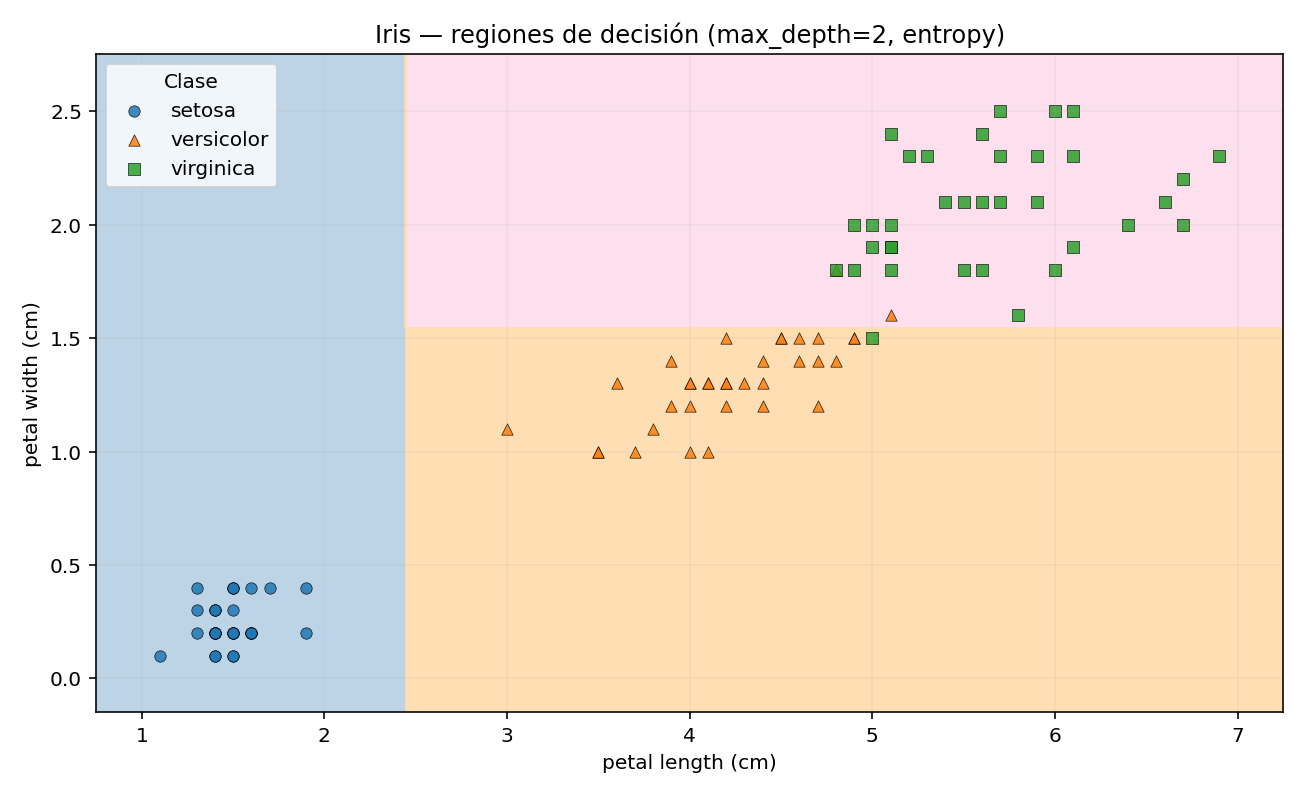

In [5]:
import sys
from IPython.display import Image, display
display(Image(filename='./ActividadesPracticas/AM_ArbolesDecision/2_imagenes/iris_entropy_h2.png', width=900))

#### ¿Cómo aprende un árbol de decisión?

En un árbol de decisión el algoritmo aprende una serie de reglas de decisión que permiten separar progresivamente los ejemplos según sus clases.

En cada nodo, evalúa distintas condiciones sobre los atributos y selecciona aquella que produce la mejor separación de los datos. Para determinar cuál es la mejor división, utiliza una medida de impureza y un criterio como la ganancia de información.

Los datos se dividen en subconjuntos y el procedimiento se repite sobre cada uno de ellos hasta alcanzar una condición de parada. 

Los nodos terminales se denominan hojas y contienen la clase que se utilizará para realizar las predicciones.

#### Entropía y ganancia de información

La **entropía** mide la impureza de un nodo que contiene observaciones de $c$ clases:

$$H(D)=-\sum_{i=1}^{c}p_i\log_2(p_i),$$

siendo $p_i$ la proporción de observaciones de la clase $i$ en $D$. Una entropía igual a cero indica que todos los ejemplos pertenecen a la misma clase. Cuanto mayor es la mezcla de clases, mayor es la entropía. 

La **ganancia de información** mide cuánto disminuye la impureza de un conjunto de datos después de realizar una división.
Se calcula como la diferencia entre la impureza del nodo padre y la impureza promedio ponderada de los nodos hijos:

$$
\boxed{IG(D,Q)=H(D)-\sum_{j=1}^{m}\frac{D_j}{D}\,H(D_j)}
$$

Donde:
- $D$: conjunto de datos del nodo que se desea dividir.
- $Q$: condición utilizada para realizar la división.
- $D_j$: subconjunto de datos correspondiente al hijo $j$.
- $m$: número de subconjuntos generados por la división.
- $H(D)$: medida de impureza del conjunto $D$.
- $D_j/D$: proporción de ejemplos que llegan al hijo $j$.

El algoritmo selecciona la condición que maximiza la reducción de impureza, obteniendo así subconjuntos más puros.

### 2. Ejemplo

Para entender en profundidad como se selecciona la característica para dividir un nodo en el algoritmo. Vamos a resolver el siguiente ejemplo:

| ID | Edad | Le gustan los perros | Le gusta la gravedad | Será astronauta |
|---:|:---:|:---:|:---:|---:|
| 1 | ≤ 40 | No | No | 0 |
| 2 | ≤ 40 | Sí | Sí | 1 |
| 3 | ≤ 40 | No | Sí | 1 |
| 4 | ≤ 40 | No | No | 0 |
| 5 | > 40 | No | No | 0 |
| 6 | > 40 | Sí | Sí | 1 |
| 7 | > 40 | Sí | No | 0 |
| 8 | > 40 | Sí | Sí | 1 |
| 9 | > 40 | No | Sí | 0 |
| 10 | > 40 | Sí | Sí | 1 |

### 3. Ejercicio 1 — Partidos de tenis (resolución manual)

En la siguiente tabla se registran datos sobre la realización o suspensión de partidos de tenis en función de distintas condiciones meteorológicas:

|| Pronóstico | Humedad | Viento | Juega |
|---:|---|---|---|---|
| 1 | soleado | alta | no | no |
| 2 | nublado | alta | no | sí |
| 3 | lluvioso | normal | no | sí |
| 4 | lluvioso | normal | sí | no |
| 5 | soleado | alta | no | no |
| 6 | soleado | normal | no | sí |
| 7 | nublado | alta | sí | sí |
| 8 | lluvioso | alta | sí | no |

**Implementar un árbol binario**, utilizando exclusivamente **entropía** como medida de impureza. 

Para los atributos con tres categorías, debe evaluarse cada condición `¿atributo = categoría?` contra **todas las categorías restantes**. Por ejemplo: `¿Pronóstico = nublado?` separa `{nublado}` de `{soleado, lluvioso}`. Para un atributo binario basta con evaluar una de sus dos condiciones complementarias.

**Parte A — Obligatoriamente en papel (sin código):**

1. Calcular la entropía de la raíz y la ganancia de información de **todas las divisiones binarias diferentes**.
2. Elegir la mejor condición, indicar cuántos casos y qué clases contiene cada rama, y repetir el cálculo solamente en los nodos que no sean puros.
3. Continuar hasta obtener un **árbol completo de hojas puras**, dibujándolo con las condiciones, etiquetas Sí/No y cantidad de ejemplos por nodo/hoja.
4. **Fotografiar las páginas manuscritas y subirlas al espacio de entrega del campus.** Deben poder verse las cuentas, las decisiones y el dibujo del árbol. No utilizar código.

**Parte B — Con Python y scikit-learn:** una vez concluida la parte A, entrenar un `DecisionTreeClassifier(criterion="entropy")` con los mismos ejemplos y comparar su estructura y sus predicciones con el árbol dibujado a mano:

1. Leer el archivo `play_tennis.csv`, comprobar los nombres de las variables y construir `X` e `y`.
2. Codifique las variables categóricas utilizando `OneHotEncoder`.
3. Entrenar un `DecisionTreeClassifier` con `criterion="entropy"` y `random_state=42`, sin limitar inicialmente la profundidad.
4. Dibujar el árbol con `plot_tree` de scikit-learn, mostrando nombres de variables, entropía, cantidad de ejemplos y clases, determinar su profundidad, cantidad de nodos y hojas.
5. Compararlo con la **resolución en papel**: ¿coinciden las divisiones? ¿Puede cambiar la orientación Sí/No de una pregunta equivalente? ¿Cómo se representa una condición categórica binaria después de `OneHotEncoder`?

### 4. Ejercicio 2 — Iris: regiones de decisión, generalización y sobreajuste

En esta actividad se trabajará con el dataset **Iris** y con dos variables continuas:

- `petal length (cm)` (longitud del pétalo).
- `petal width (cm)` (ancho del pétalo).

El objetivo es relacionar **estructura del árbol**, **regiones del espacio de características** y **diferencias entre los resultados de entrenamiento y prueba**.

**Consignas:**

1. Cargar el dataset Iris, usando `load_iris()` seleccionar únicamente las dos características indicadas. Separar **70 % para entrenamiento y 30 % para prueba** (`random_state=42`, `stratify=y`).

2. Entrenar árboles con `criterion="entropy"` y `max_depth=2` y `max_depth=3`. Graficar cada árbol y sus regiones de decisión, marcando los datos de entrenamiento.

3. Entrenar otro árbol sin límite de profundidad (`max_depth=None`). Registrar para los tres modelos: profundidad obtenida, número de hojas, accuracy de entrenamiento y accuracy de prueba. Comparar: ¿más profundidad aumenta siempre el accuracy de entrenamiento? ¿Aumenta necesariamente el de prueba?

4. Explorar una restricción de **pre-poda**, por ejemplo `min_samples_leaf=4`. Comparar profundidad, número de hojas y resultados con los de un árbol sin ese límite.

5. Explicar qué representan en `plot_tree`: `entropy`, `samples`, `value` y `class`. Relacionar al menos un umbral con una frontera visible en el gráfico de regiones.

In [7]:
def plot_decision_regions(model, X, y, class_names, feature_names, title, resolution=240):
    """Plot a 2D decision map with observed samples overlaid."""
    x_min, x_max = X[:, 0].min() - 0.35, X[:, 0].max() + 0.35
    y_min, y_max = X[:, 1].min() - 0.25, X[:, 1].max() + 0.25

    x_grid = np.linspace(x_min, x_max, resolution)
    y_grid = np.linspace(y_min, y_max, resolution)
    xx, yy = np.meshgrid(x_grid, y_grid)
    grid_points = np.column_stack([xx.ravel(), yy.ravel()])
    predictions = model.predict(grid_points).reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.contourf(xx, yy, predictions, levels=[-0.5, 0.5, 1.5, 2.5], cmap="Pastel1", alpha=0.85)
    for class_id, class_name in enumerate(class_names):
        mask = y == class_id
        ax.scatter(X[mask, 0], X[mask, 1], s=30, label=class_name,
                   edgecolors="black", linewidths=0.35, alpha=0.8)
    ax.set(xlabel=feature_names[0], ylabel=feature_names[1], title=title)
    ax.legend(title="Real class")
    fig.tight_layout()
    plt.show()